<a href="https://colab.research.google.com/github/Glenterry23/-PREDICTING-TRANSACTION-RISK-LEVELS-IN-METAVERSE-FINANCIAL-TRANSACTIONS-USING-MACHINE-LEARNING-/blob/main/Metaverse_Transaction_Risk_Classification_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.utils import resample


# 1. DATA COLLECTION

In [ ]:
df = pd.read_csv("/content/sample_data/metaverse_transactions_dataset.csv")
print("\n DATA LOADED SUCECSSFULLY")
print(df.head)


 DATA LOADED SUCECSSFULLY
<bound method NDFrame.head of               timestamp  hour_of_day  \
0      11-04-2022 12:47           12   
1      14-06-2022 19:12           19   
2      18-01-2022 16:26           16   
3      15-06-2022 09:20            9   
4      18-02-2022 14:35           14   
...                 ...          ...   
78595  13-02-2022 12:52           12   
78596  16-02-2022 16:15           16   
78597  04-08-2022 16:06           16   
78598  26-02-2022 04:06            4   
78599  25-06-2022 14:27           14   

                                  sending_address  \
0      0x9d32d0bf2c00f41ce7ca01b66e174cc4dcb0c1da   
1      0xd6e251c23cbf52dbd472f079147873e655d8096f   
2      0x2e0925b922fed01f6a85d213ae2718f54b8ca305   
3      0x93efefc25fcaf31d7695f28018d7a11ece55457f   
4      0xad3b8de45d63f5cce28aef9a82cf30c397c6ceb9   
...                                           ...   
78595  0xa99b9a7f5c5dd37429771efd3b93c6fbe1ab2936   
78596  0xcca095ad2d508c200bda1141f783d

##2. DATA DESCRIPTION

In [ ]:
print("\n SHAPE OF DATASET: ", df.shape)
print("\nDATASET INFORAMATION:\n")
print(df.info())
print("\nCOLUMN TYPES:\n")
print(df.dtypes)
print("\nNUMBER OF DUPLICATE ROWS:\n")
print(df.duplicated().sum())


 SHAPE OF DATASET:  (78600, 14)

DATASET INFORAMATION:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78600 entries, 0 to 78599
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          78600 non-null  object 
 1   hour_of_day        78600 non-null  int64  
 2   sending_address    78600 non-null  object 
 3   receiving_address  78600 non-null  object 
 4   amount             78600 non-null  float64
 5   transaction_type   78600 non-null  object 
 6   location_region    78600 non-null  object 
 7   ip_prefix          78600 non-null  float64
 8   login_frequency    78600 non-null  int64  
 9   session_duration   78600 non-null  int64  
 10  purchase_pattern   78600 non-null  object 
 11  age_group          78600 non-null  object 
 12  risk_score         78600 non-null  float64
 13  anomaly            78600 non-null  object 
dtypes: float64(3), int64(3), object(8)
memory usage: 8.4+ MB
None

### 2.1 DESCRIPTIVE STATISTICS

In [ ]:
print("\n NUMERICAL SUMMARY STATISTICS\n")
print(df.describe())

print("\nSUMMARY OF CATEGORICAL COLUMNS:")
print(df.describe(include='object'))



 NUMERICAL SUMMARY STATISTICS

        hour_of_day        amount     ip_prefix  login_frequency  \
count  78600.000000  78600.000000  78600.000000     78600.000000   
mean      11.532634    502.574903    147.644430         4.178702   
std        6.935897    245.898146     69.388143         2.366038   
min        0.000000      0.010000     10.000000         1.000000   
25%        6.000000    331.319966    172.000000         2.000000   
50%       12.000000    500.029500    172.160000         4.000000   
75%       18.000000    669.528311    192.000000         6.000000   
max       23.000000   1557.150905    192.168000         8.000000   

       session_duration    risk_score  
count      78600.000000  78600.000000  
mean          69.684606     44.956722  
std           40.524476     21.775365  
min           20.000000     15.000000  
25%           35.000000     26.250000  
50%           60.000000     40.000000  
75%          100.000000     52.500000  
max          159.000000    100.0000

### 2.2 EXPLORATORY DATA ANALYSIS

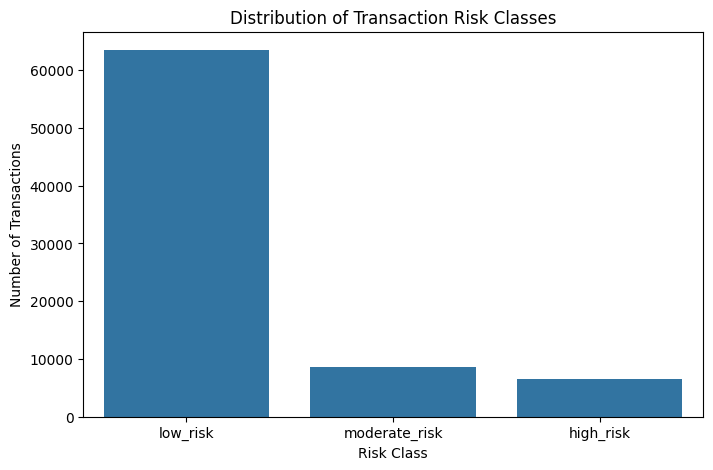

TARGET CLASS COUNTS:
anomaly
low_risk         63494
moderate_risk     8611
high_risk         6495
Name: count, dtype: int64

TARGET CLASS PERCENTAGES:
anomaly
low_risk         80.78
moderate_risk    10.96
high_risk         8.26
Name: proportion, dtype: float64


In [ ]:
# Distribution of the target classes
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='anomaly')
plt.title('Distribution of Transaction Risk Classes')
plt.xlabel('Risk Class')
plt.ylabel('Number of Transactions')
plt.show()

print('TARGET CLASS COUNTS:')
print(df['anomaly'].value_counts())

print('\nTARGET CLASS PERCENTAGES:')
print((df['anomaly'].value_counts(normalize=True) * 100).round(2))

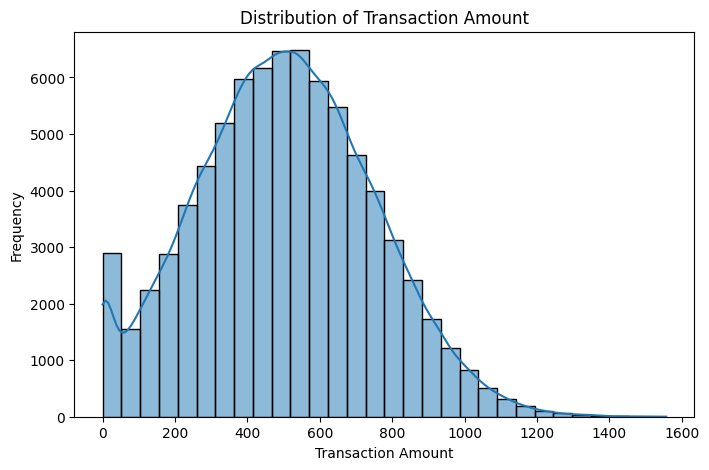

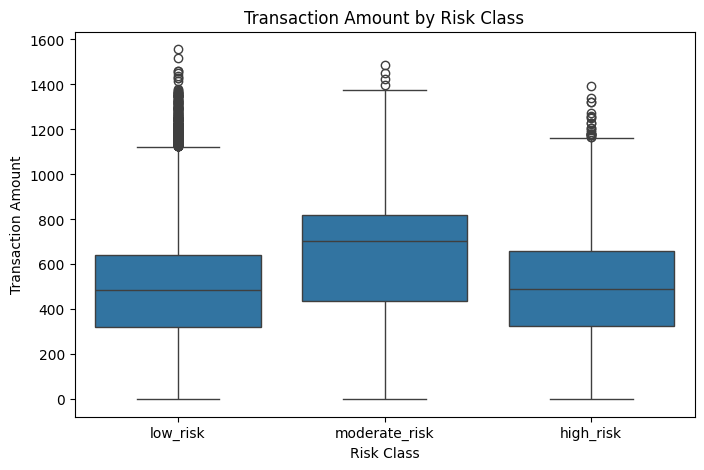

In [ ]:
# Distribution of transaction amount
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='amount', bins=30, kde=True)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

# Transaction amount by risk class
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='anomaly', y='amount')
plt.title('Transaction Amount by Risk Class')
plt.xlabel('Risk Class')
plt.ylabel('Transaction Amount')
plt.show()

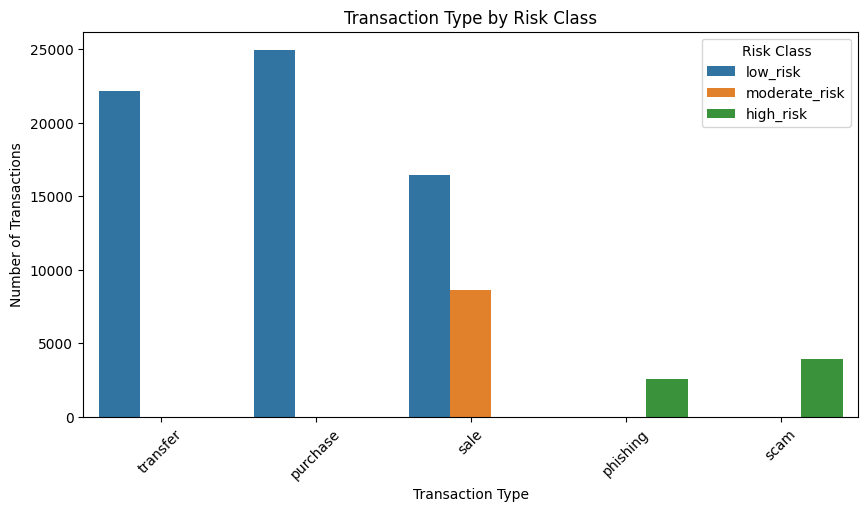

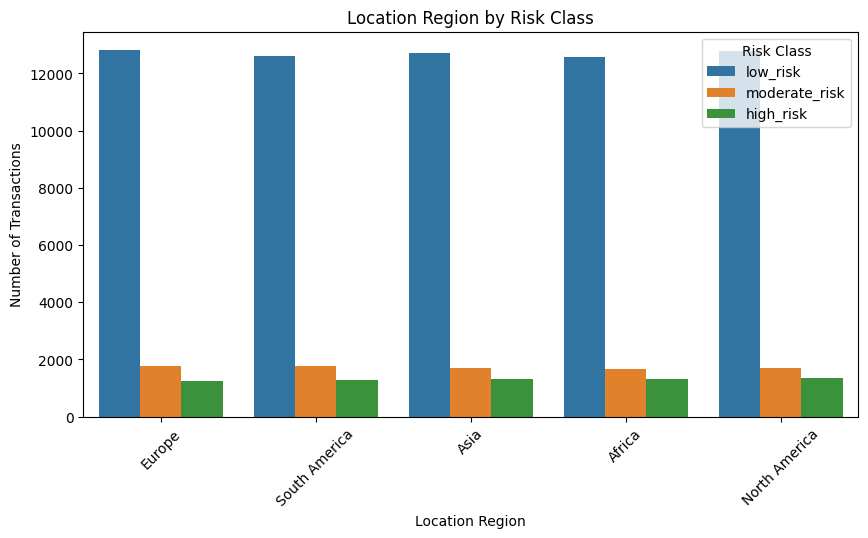

In [ ]:
# Transaction type and risk class
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='transaction_type', hue='anomaly')
plt.title('Transaction Type by Risk Class')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.legend(title='Risk Class')
plt.show()

# Location and risk class
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='location_region', hue='anomaly')
plt.title('Location Region by Risk Class')
plt.xlabel('Location Region')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.legend(title='Risk Class')
plt.show()

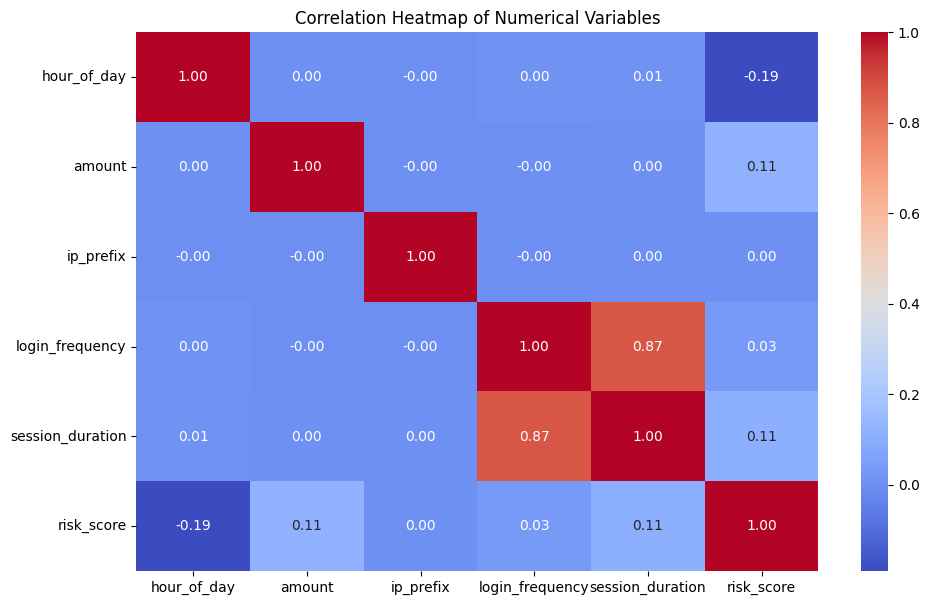

In [ ]:
# Numerical correlation heatmap
numerical_data = df.select_dtypes(include=np.number)
correlation = numerical_data.corr()

plt.figure(figsize=(11, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

##2.4 CHECKING POSSIBLE TARGET LEAKAGE

RISK SCORE BY TARGET CLASS:
                 count       mean        std   min    25%       50%       75%  \
anomaly                                                                         
high_risk       6495.0  97.686374   3.422143  90.0  94.50  100.0000  100.0000   
low_risk       63494.0  36.274932  11.834191  15.0  26.25   35.4375   49.6125   
moderate_risk   8611.0  69.200427   6.774497  62.5  62.50   67.5000   70.8750   

                    max  
anomaly                  
high_risk      100.0000  
low_risk        59.0625  
moderate_risk   84.3750  


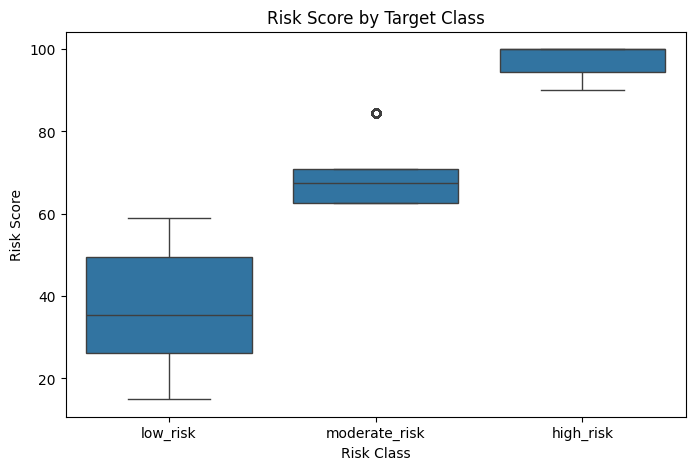

In [ ]:
# risk_score may have been used to create the anomaly label.
# Therefore, it is examined here but excluded from the main models.
if 'risk_score' in df.columns:
    print('RISK SCORE BY TARGET CLASS:')
    print(df.groupby('anomaly')['risk_score'].describe())

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='anomaly', y='risk_score')
    plt.title('Risk Score by Target Class')
    plt.xlabel('Risk Class')
    plt.ylabel('Risk Score')
    plt.show()

In [ ]:
print('MISSING VALUES BEFORE CLEANING:')
print(df.isnull().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print('\nDATASET SHAPE AFTER REMOVING DUPLICATES:', df.shape)


MISSING VALUES BEFORE CLEANING:
timestamp            0
hour_of_day          0
sending_address      0
receiving_address    0
amount               0
transaction_type     0
location_region      0
ip_prefix            0
login_frequency      0
session_duration     0
purchase_pattern     0
age_group            0
risk_score           0
anomaly              0
dtype: int64

DATASET SHAPE AFTER REMOVING DUPLICATES: (78600, 14)


# 3. DATA PREPROCESSING

## 3.1 FEATURE ENGINEERING

In [ ]:
# Convert timestamp into simple time features
df['timestamp'] = pd.to_datetime(df['timestamp'], dayfirst=True, errors='coerce')
df['hour_of_day'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

# Remove the original timestamp
df = df.drop('timestamp', axis=1)

print(df[['hour_of_day', 'day_of_week']].head())

   hour_of_day  day_of_week
0           12            0
1           19            1
2           16            1
3            9            2
4           14            4


###3.2 SELECTING FEATUERS AND ENCODING THE TARGET

In [ ]:
# Wallet addresses are identifiers and are not used as predictors.
# risk_score is excluded because it may directly determine the target label.
columns_to_remove = ['anomaly']

if 'sending_address' in df.columns:
    columns_to_remove.append('sending_address')

if 'receiving_address' in df.columns:
    columns_to_remove.append('receiving_address')

if 'risk_score' in df.columns:
    columns_to_remove.append('risk_score')

X = df.drop(columns_to_remove, axis=1)
y = df['anomaly'].copy()

# XGBoost requires target classes numbered as 0, 1 and 2.
label_mapping = {
    'low_risk': 0,
    'moderate_risk': 1,
    'high_risk': 2
}

y = y.map(label_mapping)

if y.isnull().sum() > 0:
    print('Please check the target labels. Some labels were not mapped.')
    print(df.loc[y.isnull(), 'anomaly'].unique())
else:
    y = y.astype(int)

print('FEATURES USED IN THE MODELS:')
print(X.columns.tolist())

print('\nTARGET LABEL MAPPING:')
print(label_mapping)

print('\nENCODED TARGET DISTRIBUTION:')
print(y.value_counts().sort_index())



FEATURES USED IN THE MODELS:
['hour_of_day', 'amount', 'transaction_type', 'location_region', 'ip_prefix', 'login_frequency', 'session_duration', 'purchase_pattern', 'age_group', 'day_of_week']

TARGET LABEL MAPPING:
{'low_risk': 0, 'moderate_risk': 1, 'high_risk': 2}

ENCODED TARGET DISTRIBUTION:
anomaly
0    63494
1     8611
2     6495
Name: count, dtype: int64


 ## 3.3 TRAIN TEST SPLIT

In [ ]:
# The original data are split before balancing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print('TRAINING DATA SHAPE:', X_train.shape)
print('TEST DATA SHAPE:', X_test.shape)

print('\nORIGINAL TRAINING CLASS DISTRIBUTION:')
print(y_train.value_counts().sort_index())

print('\nUNTOUCHED TEST CLASS DISTRIBUTION:')
print(y_test.value_counts().sort_index())

TRAINING DATA SHAPE: (55020, 10)
TEST DATA SHAPE: (23580, 10)

ORIGINAL TRAINING CLASS DISTRIBUTION:
anomaly
0    44446
1     6028
2     4546
Name: count, dtype: int64

UNTOUCHED TEST CLASS DISTRIBUTION:
anomaly
0    19048
1     2583
2     1949
Name: count, dtype: int64


### 3.4 HANDLING  MISSING VALUES

In [ ]:
# Missing values are filled using values calculated from training data only.
numeric_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(exclude=np.number).columns

for column in numeric_columns:
    training_median = X_train[column].median()
    X_train[column] = X_train[column].fillna(training_median)
    X_test[column] = X_test[column].fillna(training_median)

for column in categorical_columns:
    training_mode = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(training_mode)
    X_test[column] = X_test[column].fillna(training_mode)

print('MISSING VALUES IN TRAINING DATA:', X_train.isnull().sum().sum())
print('MISSING VALUES IN TEST DATA:', X_test.isnull().sum().sum())


MISSING VALUES IN TRAINING DATA: 0
MISSING VALUES IN TEST DATA: 0


#### 3.5 ENCODING CATEGORICAL FEATURES

In [ ]:
# Convert categorical features into dummy variables.
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# Give the test data exactly the same columns as the training data.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('NUMBER OF MODEL FEATURES:', X_train.shape[1])
print(X_train.head())

NUMBER OF MODEL FEATURES: 18
       hour_of_day      amount  ip_prefix  login_frequency  session_duration  \
51752           14  622.833410    172.000                7                90   
75710            4  239.650798     10.000                4                42   
56830            4  665.418675    172.000                2                23   
6377            11  399.433437    192.168                7               140   
19552           18  404.822236    172.000                7               156   

       day_of_week  transaction_type_purchase  transaction_type_sale  \
51752            3                      False                  False   
75710            6                       True                  False   
56830            3                       True                  False   
6377             0                      False                   True   
19552            0                      False                   True   

       transaction_type_scam  transaction_type_transfer  

#####3.6 SCALING

In [ ]:
# The scaler learns only from the training data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('SCALING COMPLETED')
print('Training array shape:', X_train_scaled.shape)
print('Test array shape:', X_test_scaled.shape)

SCALING COMPLETED
Training array shape: (55020, 18)
Test array shape: (23580, 18)


###### 3.7 BALANCING THE TRAINING DATA ONLY


In [ ]:
# Combine the scaled training features with the training target.
training_data = pd.DataFrame(X_train_scaled, columns=X_train.columns)
training_data['anomaly'] = y_train.reset_index(drop=True)

print('CLASS DISTRIBUTION BEFORE BALANCING:')
print(training_data['anomaly'].value_counts().sort_index())

# Find the size of the largest class.
largest_class_size = training_data['anomaly'].value_counts().max()

# Upsample each training class separately.
balanced_class_0 = resample(
    training_data[training_data['anomaly'] == 0],
    replace=True,
    n_samples=largest_class_size,
    random_state=42
)

balanced_class_1 = resample(
    training_data[training_data['anomaly'] == 1],
    replace=True,
    n_samples=largest_class_size,
    random_state=42
)

balanced_class_2 = resample(
    training_data[training_data['anomaly'] == 2],
    replace=True,
    n_samples=largest_class_size,
    random_state=42
)

balanced_training_data = pd.concat([
    balanced_class_0,
    balanced_class_1,
    balanced_class_2
])

# Shuffle the balanced training data.
balanced_training_data = balanced_training_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

X_train_balanced = balanced_training_data.drop('anomaly', axis=1)
y_train_balanced = balanced_training_data['anomaly'].astype(int)

print('\nCLASS DISTRIBUTION AFTER BALANCING:')
print(y_train_balanced.value_counts().sort_index())

print('\nThe test data have not been balanced or changed.')

CLASS DISTRIBUTION BEFORE BALANCING:
anomaly
0    44446
1     6028
2     4546
Name: count, dtype: int64

CLASS DISTRIBUTION AFTER BALANCING:
anomaly
0    44446
1    44446
2    44446
Name: count, dtype: int64

The test data have not been balanced or changed.


###4. MAJORITY-CLASS BASELINE

In [ ]:
# This simple baseline always predicts the most common training class.
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train_scaled, y_train)
baseline_predictions = baseline_model.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(y_test, baseline_predictions, average='macro', zero_division=0)
baseline_recall = recall_score(y_test, baseline_predictions, average='macro', zero_division=0)
baseline_f1 = f1_score(y_test, baseline_predictions, average='macro', zero_division=0)

print('MAJORITY BASELINE CLASSIFICATION REPORT:')
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1, 2],
    target_names=['low_risk', 'moderate_risk', 'high_risk'],
    zero_division=0
))

MAJORITY BASELINE CLASSIFICATION REPORT:
               precision    recall  f1-score   support

     low_risk       0.81      1.00      0.89     19048
moderate_risk       0.00      0.00      0.00      2583
    high_risk       0.00      0.00      0.00      1949

     accuracy                           0.81     23580
    macro avg       0.27      0.33      0.30     23580
 weighted avg       0.65      0.81      0.72     23580



###5. MACHINE-LEARNING MODELS

In [ ]:
models = {
    'GaussianNB': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(
        eval_metric='mlogloss',
        n_estimators=250,
        learning_rate=0.05,
        random_state=42
    ),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42)
}

results = {}
predictions = {}
trained_models = {}

# Add the baseline result first.
results['Majority Baseline'] = [
    baseline_accuracy,
    baseline_precision,
    baseline_recall,
    baseline_f1
]

for name, model in models.items():
    print('\nTRAINING', name)

    start_time = time.time()
    model.fit(X_train_balanced, y_train_balanced)
    training_time = time.time() - start_time

    predicted_values = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predicted_values)
    precision = precision_score(y_test, predicted_values, average='macro', zero_division=0)
    recall = recall_score(y_test, predicted_values, average='macro', zero_division=0)
    f1 = f1_score(y_test, predicted_values, average='macro', zero_division=0)

    results[name] = [accuracy, precision, recall, f1]
    predictions[name] = predicted_values
    trained_models[name] = model

    print('Training time:', round(training_time, 2), 'seconds')
    print('\nCLASSIFICATION REPORT:')
    print(classification_report(
        y_test,
        predicted_values,
        labels=[0, 1, 2],
        target_names=['low_risk', 'moderate_risk', 'high_risk'],
        digits=4,
        zero_division=0
    ))


TRAINING GaussianNB
Training time: 0.05 seconds

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

     low_risk     0.9921    0.8351    0.9069     19048
moderate_risk     0.4389    0.9512    0.6007      2583
    high_risk     1.0000    1.0000    1.0000      1949

     accuracy                         0.8615     23580
    macro avg     0.8103    0.9288    0.8358     23580
 weighted avg     0.9322    0.8615    0.8810     23580


TRAINING Random Forest


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Training time: 15.13 seconds

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

     low_risk     1.0000    0.9999    1.0000     19048
moderate_risk     0.9996    1.0000    0.9998      2583
    high_risk     1.0000    1.0000    1.0000      1949

     accuracy                         1.0000     23580
    macro avg     0.9999    1.0000    0.9999     23580
 weighted avg     1.0000    1.0000    1.0000     23580


TRAINING XGBoost
Training time: 8.1 seconds

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

     low_risk     0.9999    0.9995    0.9997     19048
moderate_risk     0.9965    0.9996    0.9981      2583
    high_risk     1.0000    1.0000    1.0000      1949

     accuracy                         0.9996     23580
    macro avg     0.9988    0.9997    0.9993     23580
 weighted avg     0.9996    0.9996    0.9996     23580


TRAINING SVM


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


Training time: 442.5 seconds

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

     low_risk     0.9998    0.9707    0.9850     19048
moderate_risk     0.8219    0.9988    0.9018      2583
    high_risk     1.0000    1.0000    1.0000      1949

     accuracy                         0.9762     23580
    macro avg     0.9406    0.9898    0.9623     23580
 weighted avg     0.9804    0.9762    0.9771     23580



##5.1 FINAL PERFORMANCE TABLE

In [ ]:
result_df = pd.DataFrame(
    results,
    index=['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
)

print('FINAL MODEL PERFORMANCE:')
print(result_df.T.round(4))

best_model = result_df.loc['Macro F1'].idxmax()
best_f1 = result_df.loc['Macro F1'].max()

print('\nBEST MODEL BASED ON MACRO F1:')
print(best_model, 'with Macro F1 =', round(best_f1, 4))

FINAL MODEL PERFORMANCE:
                   Accuracy  Macro Precision  Macro Recall  Macro F1
Majority Baseline    0.8078           0.2693        0.3333    0.2979
GaussianNB           0.8615           0.8103        0.9288    0.8358
Random Forest        1.0000           0.9999        1.0000    0.9999
XGBoost              0.9996           0.9988        0.9997    0.9993
SVM                  0.9762           0.9406        0.9898    0.9623

BEST MODEL BASED ON MACRO F1:
Random Forest with Macro F1 = 0.9999


###5.2 CONFUSION MATRICES

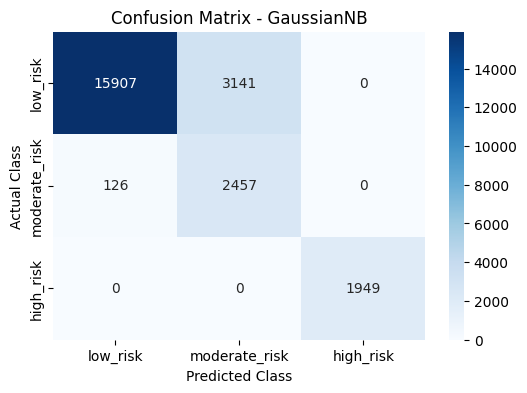

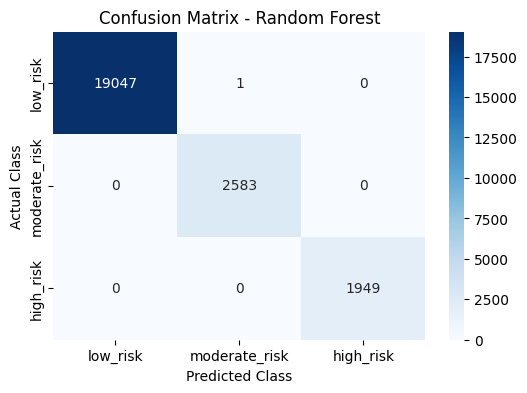

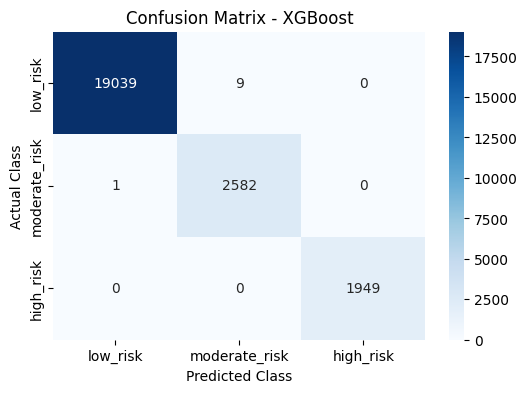

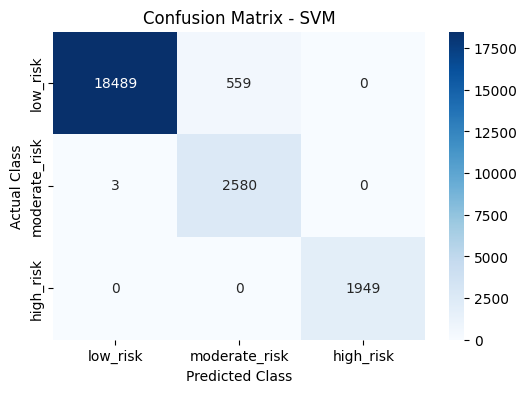

In [ ]:
for name in models.keys():
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2])

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['low_risk', 'moderate_risk', 'high_risk'],
        yticklabels=['low_risk', 'moderate_risk', 'high_risk']
    )
    plt.title('Confusion Matrix - ' + name)
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.show()

###5.3 SIMPLE CROSS-VALIDATION

In [ ]:
# Cross-validation is performed on the original training data.
# The duplicated balanced data are not used here.
print('FIVE-FOLD CROSS-VALIDATION MACRO F1 SCORES:')

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='f1_macro'
    )

    print('\n', name)
    print('Scores:', scores.round(4))
    print('Mean Macro F1:', round(scores.mean(), 4))
    print('Standard Deviation:', round(scores.std(), 4))

FIVE-FOLD CROSS-VALIDATION MACRO F1 SCORES:

 GaussianNB
Scores: [0.8376 0.838  0.8356 0.8419 0.8397]
Mean Macro F1: 0.8386
Standard Deviation: 0.0021

 Random Forest
Scores: [1.     1.     1.     1.     0.9997]
Mean Macro F1: 0.9999
Standard Deviation: 0.0001

 XGBoost
Scores: [0.9997 0.9997 0.9995 0.9995 0.9989]
Mean Macro F1: 0.9995
Standard Deviation: 0.0003

 SVM
Scores: [0.9791 0.982  0.9803 0.9822 0.9821]
Mean Macro F1: 0.9811
Standard Deviation: 0.0012


##5.4 RANDOM FOREST FEATUERS IMPORTANCE

RANDOM FOREST FEATURE IMPORTANCE:
                        Feature  Importance
7         transaction_type_sale    0.183110
9     transaction_type_transfer    0.101470
4              session_duration    0.097044
0                   hour_of_day    0.085999
6     transaction_type_purchase    0.085431
1                        amount    0.084893
3               login_frequency    0.082729
17            age_group_veteran    0.074435
15      purchase_pattern_random    0.058842
16                age_group_new    0.057021
14  purchase_pattern_high_value    0.044798
8         transaction_type_scam    0.039515
5                   day_of_week    0.002003
2                     ip_prefix    0.001526
11       location_region_Europe    0.000325


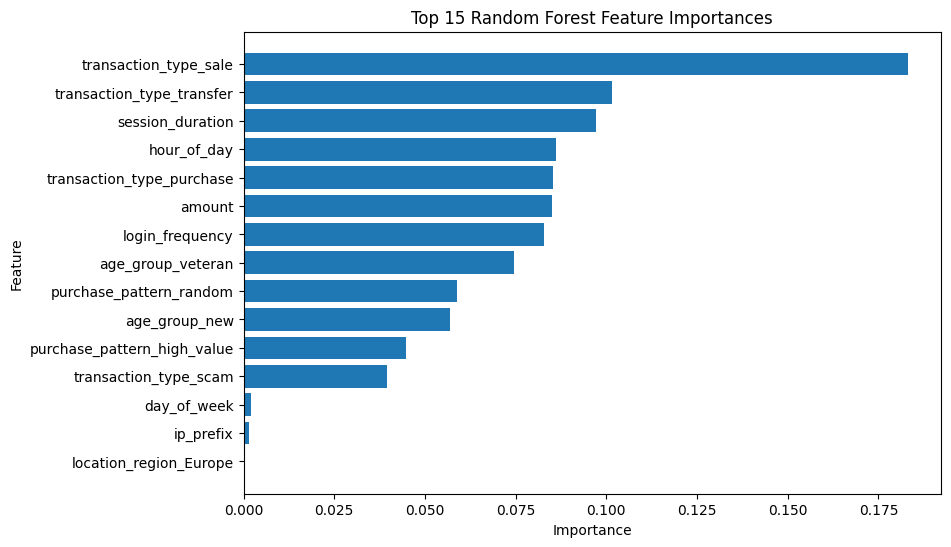

In [ ]:
# Random Forest provides a simple feature-importance measure.
random_forest_model = trained_models['Random Forest']

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

print('RANDOM FOREST FEATURE IMPORTANCE:')
print(feature_importance.head(15))

top_features = feature_importance.head(15).sort_values('Importance')

plt.figure(figsize=(9, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()